In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.feature_selection import SelectKBest, chi2

In [2]:
data = pd.read_csv('IDA_dataset_enriched_fixed.csv')
data_original = data.copy()

In [3]:
data.duplicated().sum()

np.int64(0)

In [4]:
data.isnull().sum()

Hemoglobin             0
RDW                    0
MCV                    0
Age                    0
Gender                 0
Anemia_Type            0
Pregnancy_Status     512
Medical_History      747
Activity_Level         0
Tea_Coffee_Intake    133
dtype: int64

In [5]:
data.loc[data['Gender'] == 'Male', 'Pregnancy_Status'] = 'Not Applicable'
data.to_csv('IDA_dataset_enriched_fixed.csv', index=False)


In [6]:
cat_col = [col for col in data.columns if data[col].dtype == 'object']
num_col = [col for col in data.columns if data[col].dtype != 'object']
print(cat_col)
print(num_col)

['Gender', 'Anemia_Type', 'Pregnancy_Status', 'Medical_History', 'Activity_Level', 'Tea_Coffee_Intake']
['Hemoglobin', 'RDW', 'MCV', 'Age']


In [7]:
data.to_csv('IDA_dataset_enriched_fixed.csv', index=False)

In [8]:
def outliers(col):
    q = data[col].quantile(0.25)
    qq = data[col].quantile(0.75)
    IQR = qq - q
    lower = q - 1.5*IQR
    upper = qq + 1.5*IQR
    data[col] = data[col].clip(lower, upper)

for col in num_col:
    outliers(col)

In [ ]:
le = LabelEncoder()
for col in cat_col:
    data[col] = le.fit_transform(data[col])

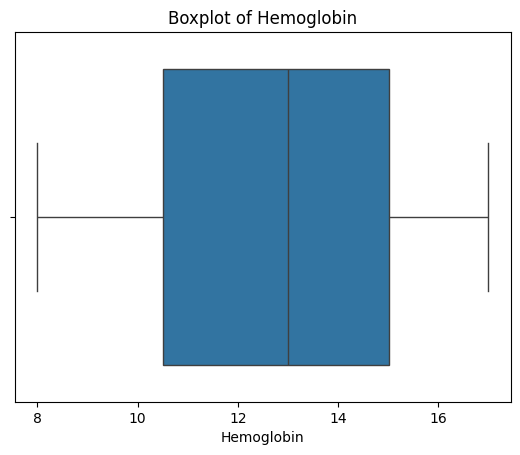

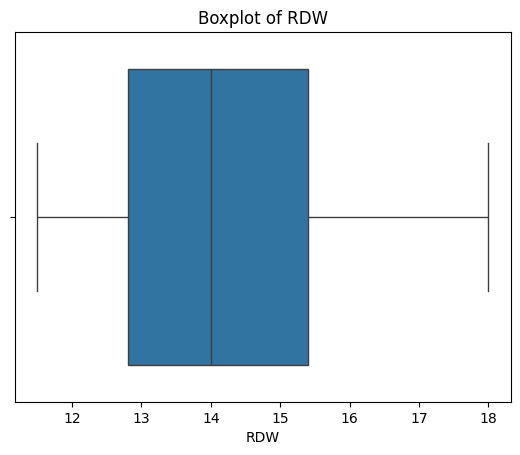

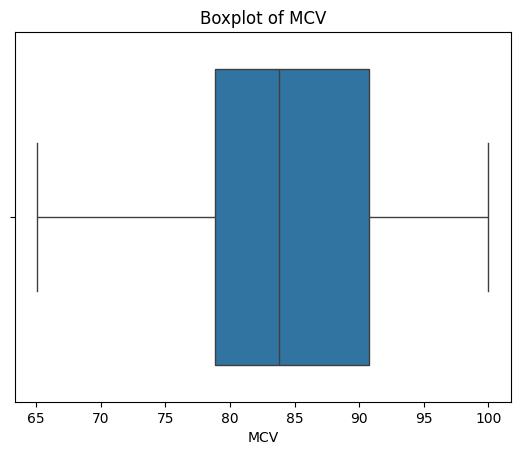

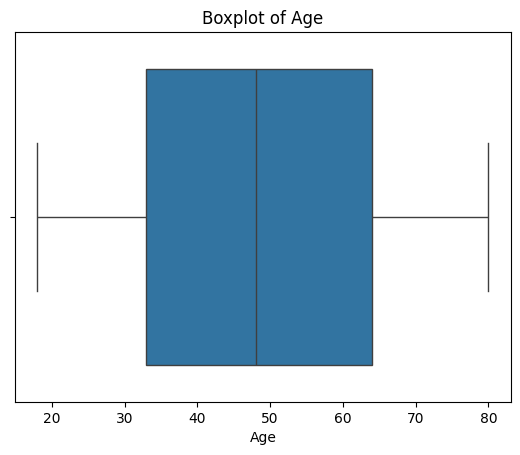

In [ ]:
for col in num_col:
    plt.figure()
    sns.boxplot(x=data[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

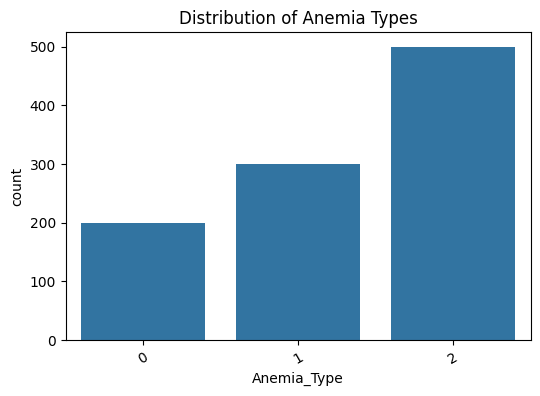

In [ ]:
# Distribution of target
plt.figure(figsize=(6,4))
sns.countplot(x='Anemia_Type', data=data)
plt.title('Distribution of Anemia Types')
plt.xticks(rotation=30)
plt.show()

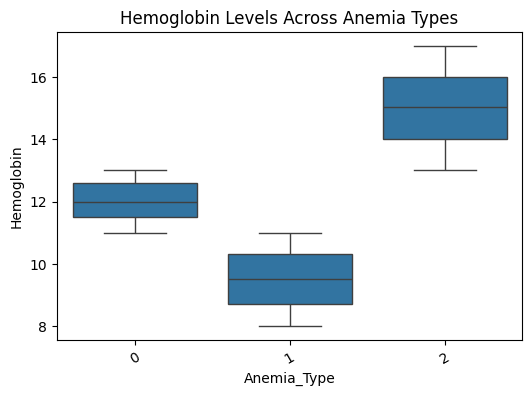

In [ ]:
# Hemoglobin levels across Anemia Types
plt.figure(figsize=(6,4))
sns.boxplot(x='Anemia_Type', y='Hemoglobin', data=data)
plt.title('Hemoglobin Levels Across Anemia Types')
plt.xticks(rotation=30)
plt.show()

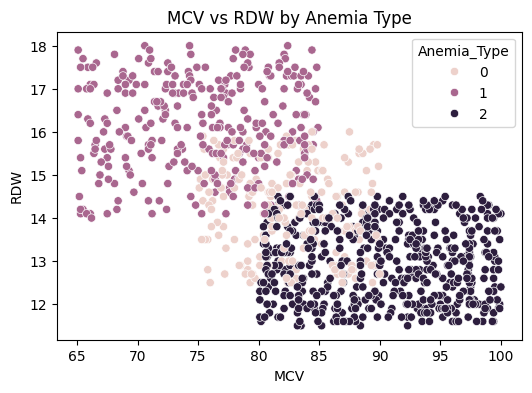

In [ ]:
# MCV vs RDW scatterplot
plt.figure(figsize=(6,4))
sns.scatterplot(x='MCV', y='RDW', hue='Anemia_Type', data=data)
plt.title('MCV vs RDW by Anemia Type')
plt.show()

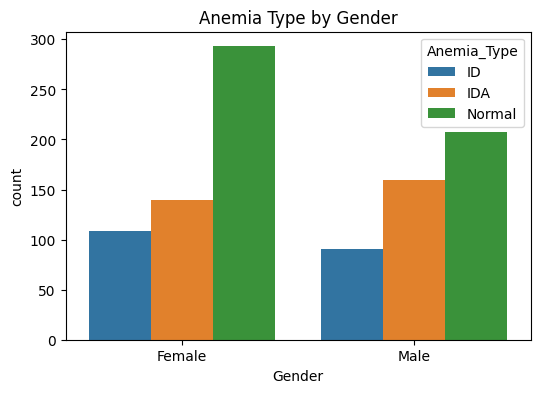

In [ ]:
# Anemia type by Gender
plt.figure(figsize=(6,4))
sns.countplot(x='Gender', hue='Anemia_Type', data=data_original)
plt.title('Anemia Type by Gender')
plt.show()

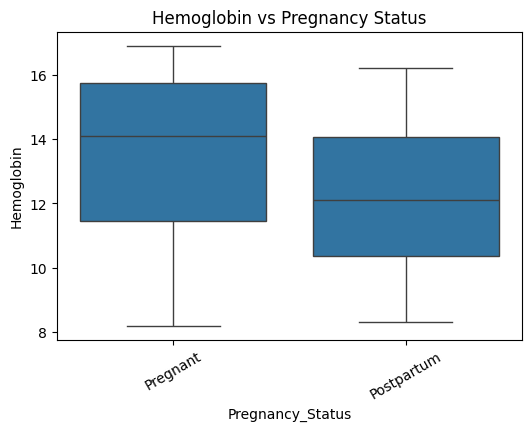

In [ ]:
# Hemoglobin vs Pregnancy Status
plt.figure(figsize=(6,4))
sns.boxplot(x='Pregnancy_Status', y='Hemoglobin', data=data_original)
plt.title('Hemoglobin vs Pregnancy Status')
plt.xticks(rotation=30)
plt.show()

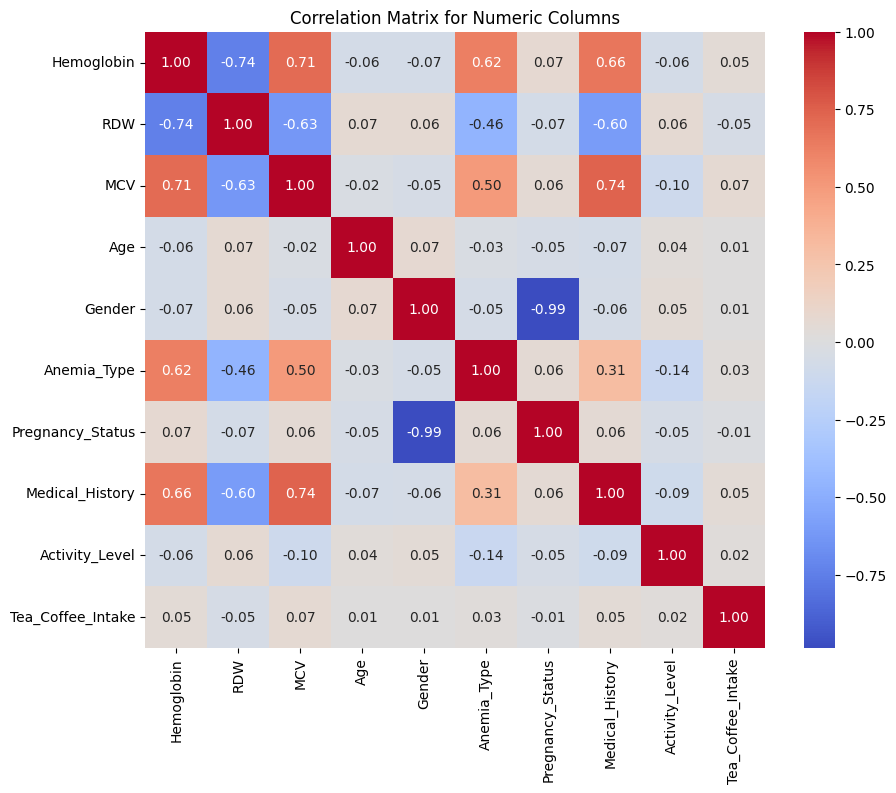

In [ ]:
# Correlation heatmap
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(10,8))
sns.heatmap(data[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix for Numeric Columns')
plt.show()

In [ ]:
#feature Engineering ده علشان نعمل مستويات
data['Hb_Level'] = pd.cut(
    data['Hemoglobin'],
    bins=[0, 10, 12, 20],
    labels=['Low', 'Medium', 'Normal']
)

In [ ]:
#علشان نحول رقمين لحالة واحدة
data['Cell_Status'] = np.where(
    (data['MCV'] < 80) & (data['RDW'] > 14),
    'Abnormal',
    'Normal'
)

In [ ]:
#تجميع اعمدة الدم
data['Blood_Score'] = (
    data['Hemoglobin'] +
    data['RDW'] +
    data['MCV']
) / 3

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

hb_encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'Normal']])     #-> النوع ده من التشفير بيستخدم لما يكون عندي  ترتيب عايز احافظ عليه low<medium<normal
data['Hb_Level'] = hb_encoder.fit_transform(data[['Hb_Level']])

In [ ]:
data['Cell_Status'] = le.fit_transform(data['Cell_Status'])

In [ ]:
#======================feature selection======================
corr = data.corr()['Anemia_Type'].sort_values(ascending=False)  #->نشوف أنهي Features أقرب للهدف
print(corr)

Anemia_Type          1.000000
Hemoglobin           0.621742
Blood_Score          0.538324
MCV                  0.498217
Hb_Level             0.449401
Cell_Status          0.340625
Medical_History      0.309475
Pregnancy_Status     0.060488
Tea_Coffee_Intake    0.027151
Age                 -0.025830
Gender              -0.054994
Activity_Level      -0.137212
RDW                 -0.464341
Name: Anemia_Type, dtype: float64


In [ ]:
#%%======Random Forest Feature Importance======
X = data.drop('Anemia_Type', axis=1)
y = data['Anemia_Type']
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns)
importances.sort_values(ascending=False)

Hemoglobin           0.459007
Hb_Level             0.181198
RDW                  0.146751
MCV                  0.069618
Blood_Score          0.059323
Cell_Status          0.034170
Medical_History      0.029949
Activity_Level       0.008850
Age                  0.006834
Tea_Coffee_Intake    0.002383
Pregnancy_Status     0.001117
Gender               0.000800
dtype: float64

In [ ]:
#%%======Select Best=========

X_scaled = MinMaxScaler().fit_transform(X)    #-> عشان ال chi2 مبيقبلش قيم سالبة ف ده بيخليلي القيم بين ال 0 و 1

selector = SelectKBest(score_func=chi2, k=5)                         
                                                            #             بيقارن بين:
                                                            # القيم اللي حصلت فعليًا
                                                            # و القيم اللي كان مفروض تحصل لو مفيش علاقة
                                                            # لو الفرق كبير -> feature مهمة
                                                            # لو الفرق صغير -> feature ضعيفة
                                                            # شغال كويس مع:
                                                            # Classification
                                                            # Features encoded
                                                            # مشاكل طبية وتصنيفية
X_selected = selector.fit_transform(X_scaled, y)

selected_features = X.columns[selector.get_support()]
print(selected_features)

Index(['Hemoglobin', 'RDW', 'Medical_History', 'Hb_Level', 'Cell_Status'], dtype='object')


In [ ]:
#%%===== FINAL DATA FOR MODELING =====

final_features = selected_features.tolist()
X_final = data[final_features]
y = data['Anemia_Type']

In [ ]:
#%% ======================train/test split======================

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y,
    test_size=0.2,
    random_state=42,
    stratify=y   # مهم علشان التوزيع
)

In [ ]:
#%%======================Scaling=====================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#%%======================Logistic Regression======================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#====================== Logistic Regression ======================
lr = LogisticRegression(max_iter=200)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.975
              precision    recall  f1-score   support

           0       0.97      0.90      0.94        40
           1       0.97      0.98      0.98        60
           2       0.98      1.00      0.99       100

    accuracy                           0.97       200
   macro avg       0.97      0.96      0.97       200
weighted avg       0.97      0.97      0.97       200



In [ ]:
#===================Decision Tree============================
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))

Decision Tree Accuracy: 0.995


In [ ]:
# %%====================Random Forest============================

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.995
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        40
           1       0.98      1.00      0.99        60
           2       1.00      1.00      1.00       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



In [ ]:
# %%====================knn============================
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 0.985


In [ ]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_knn)
    ]
})

In [ ]:
print(results)

                 Model  Accuracy
0  Logistic Regression     0.975
1        Decision Tree     0.995
2        Random Forest     0.995
3                  KNN     0.985


In [ ]:
# ======================= Test New Patient (Random Forest) =======================

new_patient = pd.DataFrame([{
    'Hemoglobin': 9.2,
    'RDW': 15.8,
    'MCV': 76,
    'Age': 28,
    'Gender': 1,              # Female
    'Pregnancy_Status': 1,    # Pregnant
    'Medical_History': 1,
    'Activity_Level': 2,
    'Tea_Coffee_Intake': 3,
    'Hb_Level': 0,            # Low
    'Cell_Status': 1,         # Abnormal
    'Blood_Score': (9.2 + 15.8 + 76) / 3
}])

# نفس الـ features اللي اتدرّب عليها الموديل
new_patient = new_patient[selected_features]

# التنبؤ باستخدام Random Forest
prediction = rf.predict(new_patient)

print("Predicted Anemia Type:", prediction)
